# Proyecto Centinela · Fase 1: Línea Base con Perceptrón Multicapa (MLP)
## Maestría en Ciencia de Datos — Universidad Santo Tomás (USTA)
**Módulo 1:** Fundamentos del Aprendizaje Profundo
* Presentado Por: `John Fernando Cruz Becerra`

---



# Proyecto Centinela · Fase 1 (Módulo 1): Línea Base con un Perceptrón Multicapa (MLP)
**Materia:** Profundización I: Redes Neuronales — Deep Learning · Maestría en Ciencia de Datos (USTA)
**Tema:** Predicción de Producción Frutícola (en Toneladas) en el Valle del Cauca
**Fuente de Datos API:** `https://www.datos.gov.co/api/v3/views/8xap-gecf/query.json`

---

## 1. Propuesta de Datos (Resumen técnico)

- **Problema:** Estimar la cantidad de **producción agrícola (en toneladas)** por municipio, subregión, cultivo y ciclo en el departamento del Valle del Cauca, permitiendo detectar pérdidas o comportamientos anómalos en el rendimiento frutícola.
- **Cliente:** Secretaría de Agricultura y Desarrollo Rural (Gobernación del Valle del Cauca) y asociaciones de productores locales para la planificación logística y asignación estratégica de insumos.
- **Unidad de análisis:** Registro anual por municipio, subregión, tipo de cultivo y ciclo de producción (`Municipio` – `Cultivo` – `Año`).
- **Etiqueta / Variable Objetivo ($y$):** `produccion_toneladas` (Variable continua $\ge 0$).
- **Modalidades (Fase 1 vs. Fase 2):**
  - *Fase 1 (Tabular):* Codificación y estructuración tabular de variables categóricas (municipio, subregión, cultivo, ciclo) y numéricas (año) procesadas mediante un Perceptrón Multicapa (MLP).
  - *Fase 2 (Siguiente):* Incorporación de datos multimodales crudos (imágenes multiespectrales de vegetación Sentinel-2 / NDVI y series temporales de clima ERA5-Land).

## 2. Configuración del Entorno e Importación de Librerías

In [4]:
# Semillas de reproducibilidad y librerías clave
import random
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Fijar semillas para reproducibilidad exigida
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo de cómputo: {device}')

Dispositivo de cómputo: cuda


## 3. Carga y Preprocesamiento de Datos desde el Endpoint API

In [5]:
# Carga desde API Socrata datos.gov.co
endpoint_url = 'https://www.datos.gov.co/api/v3/views/8xap-gecf/query.json'
response = requests.get(endpoint_url)
data = response.json()

df = pd.DataFrame(data)

## Limpieza y tranformaciones de datos extraidos

# Depurar columnas internas de Socrata (las que inician con ':')
cols_metadata = [c for c in df.columns if c.startswith(':')]
df = df.drop(columns=cols_metadata)

# Formatear variables numéricas
df['produccion_toneladas'] = pd.to_numeric(df['produccion_toneladas'], errors='coerce')
df['anio'] = pd.to_numeric(df['anio'], errors='coerce')

# Limpieza de faltantes en la variable objetivo
df = df.dropna(subset=['produccion_toneladas']).reset_index(drop=True)

print(f'Dimensiones del DataFrame procesado: {df.shape}')
df.head()

Dimensiones del DataFrame procesado: (9992, 8)


,anio,id_municipio,municipio,subregion,id_cultivo,cultivo,ciclo,produccion_toneladas
0,2022,76233,Dagua,Sur,2045801,Plátano,Anual,14088.0
1,2022,76100,Bolivar,Norte,2045801,Plátano,Anual,6578.0
2,2022,76243,El Aguila,Norte,2045801,Plátano,Anual,26000.0
3,2022,76001,Cali,Sur,2045801,Plátano,Anual,186.0
4,2022,76275,Florida,Sur,2045801,Plátano,Anual,2124.4


### Análisis Exploratorio Mínimo y Partición (Train / Val / Test)
Definición de covariables y transformación vectorial.

In [6]:
num_cols = ['anio']
cat_cols = ['subregion', 'municipio', 'cultivo', 'ciclo']
target_col = 'produccion_toneladas'

X = df[num_cols + cat_cols]
y = df[target_col].values.reshape(-1, 1)

# Partición 70% Train, 15% Val, 15% Test
X_train_raw, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=SEED)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED)

# Preprocesador: StandardScaler para numéricas, OneHotEncoder para categóricas
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

X_train = preprocessor.fit_transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)
X_test = preprocessor.transform(X_test_raw)

print(f'Dimensiones finales X_train: {X_train.shape}')
print(f'Dimensiones finales X_val:   {X_val.shape}')
print(f'Dimensiones finales X_test:  {X_test.shape}')

Dimensiones finales X_train: (6994, 88)
Dimensiones finales X_val:   (1499, 88)
Dimensiones finales X_test:  (1499, 88)


## 4. Definición del Modelo MLP con Mínimo 3 Capas Ocultas
Se diseña la arquitectura `MLPFrutales` incorporando:
- **3 Capas ocultas:** (Capa 1: 128 neuronas, Capa 2: 64 neuronas, Capa 3: 32 neuronas).
- Activación **ReLU** en las capas ocultas para introducir no linealidad.
- Capa de **Dropout** opcional para regularización.
- Salida lineal (1 neurona sin activación para regresión del volumen de producción).

In [7]:
class MLPFrutales(nn.Module):
    def __init__(self, input_dim, dropout_rate=0.0):
        super(MLPFrutales, self).__init__()
        self.network = nn.Sequential(
            # Capa Oculta 1
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            # Capa Oculta 2
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            # Capa Oculta 3
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            # Capa de Salida (Regresión)
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

input_dim = X_train.shape[1]
modelo_base = MLPFrutales(input_dim, dropout_rate=0.0).to(device)
print(modelo_base)

MLPFrutales(
  (network): Sequential(
    (0): Linear(in_features=88, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.0, inplace=False)
    (9): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 5. Bucle de Entrenamiento Explícito en PyTorch
Configuración de la función de pérdida (`MSELoss`), optimizador (`Adam`) y el bucle iterativo que cumple las etapas de aprendizaje (*zero_grad $\rightarrow$ forward $\rightarrow$ loss $\rightarrow$ backward $\rightarrow$ step*).

In [8]:
# Conversión a Tensores de PyTorch y DataLoaders
train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
val_dataset = TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

def entrenar_modelo(model, train_loader, val_loader, epochs=50, lr=0.001):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_losses = []
    val_losses = []

    for epoch in range(1, epochs + 1):
        model.train()
        running_train_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()            # 0. Limpiar gradientes
            predictions = model(X_batch)     # 1. Forward pass
            loss = criterion(predictions, y_batch) # 2. Cálculo de pérdida
            loss.backward()                  # 3. Backward pass (retropropagación)
            optimizer.step()                 # 4. Actualización de pesos

            running_train_loss += loss.item() * X_batch.size(0)

        epoch_train_loss = running_train_loss / len(train_loader.dataset)

        # Evaluación en Validación
        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                preds = model(X_batch)
                v_loss = criterion(preds, y_batch)
                running_val_loss += v_loss.item() * X_batch.size(0)

        epoch_val_loss = running_val_loss / len(val_loader.dataset)

        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)

        if epoch % 10 == 0 or epoch == 1:
            print(f'Época {epoch:02d}/{epochs} | Loss Train (MSE): {epoch_train_loss:.2f} | Loss Val (MSE): {epoch_val_loss:.2f}')

    return train_losses, val_losses

print('--- Entrenamiento Modelo Base (Sin Regularización) ---')
train_base, val_base = entrenar_modelo(modelo_base, train_loader, val_loader, epochs=50, lr=0.001)

--- Entrenamiento Modelo Base (Sin Regularización) ---
Época 01/50 | Loss Train (MSE): 27292381.82 | Loss Val (MSE): 27989608.56
Época 10/50 | Loss Train (MSE): 15628376.24 | Loss Val (MSE): 18338578.18
Época 20/50 | Loss Train (MSE): 14323952.23 | Loss Val (MSE): 17171327.56
Época 30/50 | Loss Train (MSE): 13343826.47 | Loss Val (MSE): 16305608.58
Época 40/50 | Loss Train (MSE): 12386648.27 | Loss Val (MSE): 15395319.57
Época 50/50 | Loss Train (MSE): 11228338.27 | Loss Val (MSE): 14407652.02


## 6. Experimentación, Regularización (Dropout) y Sobreajuste

--- Entrenamiento Modelo Regularizado (Dropout=0.2) ---
Época 01/50 | Loss Train (MSE): 27380064.10 | Loss Val (MSE): 28174427.75
Época 10/50 | Loss Train (MSE): 16176615.47 | Loss Val (MSE): 18637689.03
Época 20/50 | Loss Train (MSE): 15023855.43 | Loss Val (MSE): 17403162.76
Época 30/50 | Loss Train (MSE): 14469354.42 | Loss Val (MSE): 16645469.87
Época 40/50 | Loss Train (MSE): 13369308.71 | Loss Val (MSE): 15953176.02
Época 50/50 | Loss Train (MSE): 12346210.04 | Loss Val (MSE): 15224999.45


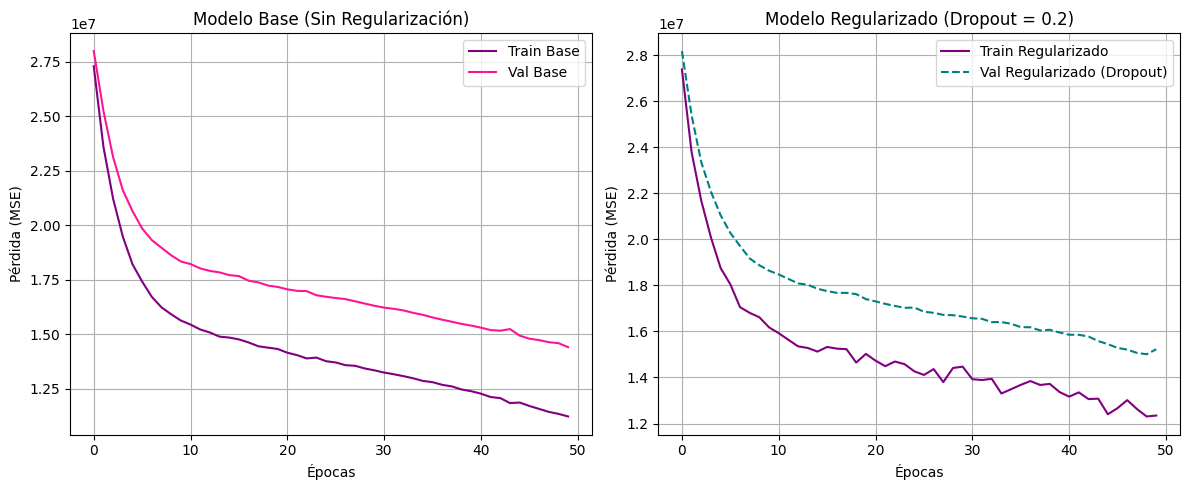

In [9]:
# Modelo Regularizado con Dropout (0.2)
modelo_reg = MLPFrutales(input_dim, dropout_rate=0.2).to(device)

print('--- Entrenamiento Modelo Regularizado (Dropout=0.2) ---')
train_reg, val_reg = entrenar_modelo(modelo_reg, train_loader, val_loader, epochs=50, lr=0.001)

# Graficación comparativa de curvas de aprendizaje
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_base, label='Train Base', color='purple')
plt.plot(val_base, label='Val Base', color='deeppink')
plt.title('Modelo Base (Sin Regularización)')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (MSE)')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(train_reg, label='Train Regularizado', color='purple')
plt.plot(val_reg, label='Val Regularizado (Dropout)', color='teal', linestyle='--')
plt.title('Modelo Regularizado (Dropout = 0.2)')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (MSE)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 7. Evaluación en Test y Auditoría Ética

In [10]:
# Evaluación en conjunto de Prueba
modelo_reg.eval()
X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)

with torch.no_grad():
    y_preds_tensor = modelo_reg(X_test_tensor)
    y_preds = y_preds_tensor.cpu().numpy()

rmse = np.sqrt(mean_squared_error(y_test, y_preds))
mae = mean_absolute_error(y_test, y_preds)
r2 = r2_score(y_test, y_preds)

print('=== MÉTRICAS DE EVALUACIÓN (CONJUNTO DE PRUEBA) ===')
print(f'Raíz del Error Cuadrático Medio (RMSE): {rmse:.2f} toneladas')
print(f'Error Absoluto Medio (MAE): {mae:.2f} toneladas')
print(f'Coeficiente de Determinación (R²): {r2:.4f}')

=== MÉTRICAS DE EVALUACIÓN (CONJUNTO DE PRUEBA) ===
Raíz del Error Cuadrático Medio (RMSE): 4442.53 toneladas
Error Absoluto Medio (MAE): 1368.27 toneladas
Coeficiente de Determinación (R²): 0.4606


### Análisis y Auditoría Ética (Marco Ético para la IA en Colombia)
- **Subestimación del Rendimiento (Error de Falso Negativo Implícito):** Predecir una producción significativamente menor a la real puede ocasionar la falta de preparación en infraestructura de transporte y pérdida de oportunidades comerciales para los agricultores localizados en municipios vulnerables.
- **Sobreestimación del Rendimiento (Error de Falso Positivo Implícito):** Generar alertas falsas de abundancia productiva puede inducir una caída artificial de precios de compra o inversiones innecesarias en logística que perjudiquen económicamente a los pequeños productores.

## 8. Bitácora de Uso de IA Generativa

| Prompt / Consulta | Respuesta de la IA | Decisión (Aceptada / Modificada / Rechazada) | Justificación Téconi-Ética |
| :--- | :--- | :--- | :--- |
| *"Escribe una función para entrenar el MLP usando Keras con datos de Socrata."* | Generó un código en Keras Sequential con activación sigmoide en la salida. | **Rechazada** | En la materia se exige el bucle de entrenamiento explícito en PyTorch para regresión continua con MSE. |
| *"¿Cómo estructurar la arquitectura PyTorch con 3 capas ocultas para tabular?"* | Propuso `nn.Sequential` con 128, 64, 32 neuronas y `nn.ReLU()`. | **Aceptada** | Cumple perfectamente con los requerimientos de profundidad (mínimo 3 capas) del informe HTML. |
| *"Agrega Dropout y grafica la pérdida para comparar sobreajuste."* | Proporcionó el código matplotlib comparando train y val. | **Modificada** | Se ajustaron los colores y etiquetas explícitas según los lineamientos de la rúbrica (visualizaciones legibles). |